# Customer happiness: seed 42

Repeat the modeling workflow with seed **42**. Use the shared scripts for data
checks, splitting, model selection, and evaluation. All other settings come
from `happy_customers.config`.

Run these five code cells in order using the project environment (`uv sync`).
See the [first notebook](1.0-CTA-customer-happiness-analysis.ipynb) for detailed
exploration and explanations.

## 1. Setup

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

from happy_customers import config
from happy_customers.train import evaluate_model, load_data, split_data, train_models

SEED = 42
SCORING = config.SCORING
TEST_SIZE = config.TEST_SIZE
CV_FOLDS = config.CV_FOLDS

print(f"Seed: {SEED}; scoring: {SCORING}; test fraction: {TEST_SIZE}; CV folds: {CV_FOLDS}")

Seed: 42; scoring: f1; test fraction: 0.12; CV folds: 10


## 2. Load and split the data

Validate the survey and reserve the test responses.

In [2]:
data = load_data()
X_train, X_test, y_train, y_test = split_data(data, seed=SEED, test_size=TEST_SIZE)

print(f"Training responses: {len(X_train)}")
print(f"Test responses: {len(X_test)}")

Training responses: 110
Test responses: 16


## 3. Compare models

Use the same six models, parameter grids, and question counts as the first
notebook. Show only the chosen CV metric and its standard deviation.

In [3]:
final_model, results, baseline_cv = train_models(
    X_train, y_train, seed=SEED, scoring=SCORING, cv_folds=CV_FOLDS
)
print(f"Majority-class mean CV {SCORING}: {baseline_cv:.3f}")
display(results.drop_duplicates("model").drop(columns="params").reset_index(drop=True).round(3))

Searching Logistic regression...


Searching KNN...


Searching SVM...


Searching Decision tree...


Searching Random forest...


Searching XGBoost...


Majority-class mean CV f1: 0.706


,model,questions,cv_f1,cv_f1_std
0,KNN,4,0.740,0.120
1,Decision tree,2,0.732,0.122
2,Logistic regression,2,0.711,0.073
3,SVM,4,0.710,0.061
4,XGBoost,1,0.706,0.000
5,Random forest,2,0.692,0.152


## 4. Review the selected questions

For the winning model, compare the best CV score at each question count.
The shared training function prefers fewer questions when scores tie exactly.

In [4]:
best = results.iloc[0]
question_results = (
    results.loc[results["model"].eq(best["model"])]
    .drop_duplicates("questions")
    .sort_values("questions")
)
display(question_results.drop(columns=["model", "params"]).reset_index(drop=True).round(3))

selected_features = final_model.named_steps["select"].get_feature_names_out().tolist()
removed_features = [name for name in config.FEATURE_COLUMNS if name not in selected_features]
print(f"Selected model: {best['model']}")
print(f"Selected parameters: {best['params']}")
print(f"Keep: {', '.join(selected_features)}")
print(f"Candidates to remove: {', '.join(removed_features) or 'None'}")

,questions,cv_f1,cv_f1_std
0,1,0.602,0.116
1,2,0.673,0.128
2,3,0.666,0.170
3,4,0.740,0.120
4,5,0.663,0.181
5,6,0.659,0.093


Selected model: KNN
Selected parameters: {'model__n_neighbors': 7, 'model__weights': 'uniform', 'select__k': 4}
Keep: X1, X3, X5, X6
Candidates to remove: X2, X4


## 5. Final test

Evaluate the fixed model and questions on the reserved responses. Show F1 for
happy customers, macro F1, and accuracy. The F1 target still applies to happy
customers (`Y=1`).

,model,questions,test_responses,test_f1,test_f1_macro,test_accuracy,F1_target_met
0,KNN,4,16,0.842,0.806,0.812,True


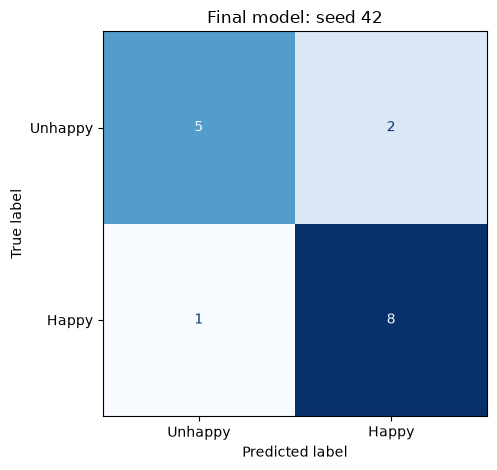

In [5]:
test_predictions, test_scores = evaluate_model(final_model, X_test, y_test)
display(pd.DataFrame([{
    "model": best["model"],
    "questions": len(selected_features),
    "test_responses": len(y_test),
    **test_scores,
}]).round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1], display_labels=["Unhappy", "Happy"],
    cmap="Blues", colorbar=False,
)
plt.title(f"Final model: seed {SEED}")
plt.tight_layout()
plt.show()